# Data Hunter Challenge — Collecte de données Web

**TD Data Mining** · Trois méthodes d'extraction comparées sur trois sources différentes.

| Mission | Méthode | Source | Sortie |
|---|---|---|---|
| 1 — Static Web Scraping | `requests` + `BeautifulSoup` | books.toscrape.com | `data/books.csv` |
| 2 — API Explorer | `requests` + API REST | Open Library Search API | `data/openlibrary.csv` |
| 3 — Dynamic Web Scraping | `Selenium` + `WebDriverWait` | quotes.toscrape.com/js | `data/quotes.csv` |

Le notebook se termine par un **audit qualité** des trois jeux de données et par la **question de conclusion** (prétraitement avant Data Mining).

## 0. Préparation

In [1]:
# À exécuter une seule fois (installe les bibliothèques dans le kernel actif)
%pip install -q requests beautifulsoup4 pandas selenium

Note: you may need to restart the kernel to use updated packages.


In [1]:
import re
import time
from pathlib import Path
from urllib.parse import urljoin

import pandas as pd
import requests
from bs4 import BeautifulSoup

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

# En-tête identifiant notre programme (bonne pratique pour les sites et les API)
HEADERS = {"User-Agent": "DataHunterChallenge/1.0 (projet etudiant Data Mining)"}

---
## Mission 1 — Static Web Scraping (Requests + BeautifulSoup)

### 1.1 Analyse de la structure HTML

En inspectant https://books.toscrape.com/ (clic droit → *Inspecter*), chaque livre est un bloc :

```html
<article class="product_pod">
  <p class="star-rating Three"></p>            <!-- note : 2e classe en toutes lettres -->
  <h3><a href="..." title="A Light in the Attic">A Light in the ...</a></h3>  <!-- titre complet dans l'attribut title -->
  <div class="product_price">
    <p class="price_color">£51.77</p>           <!-- prix sous forme de texte -->
    <p class="instock availability">In stock</p>
  </div>
</article>
```

Pagination : un lien `<li class="next"><a href="page-2.html">next</a></li>` en bas de page. Il disparaît sur la dernière page, ce qui sert de condition d'arrêt.

Points d'attention :
- le texte du `<a>` est **tronqué** (« A Light in the ... »), il faut lire l'attribut `title` ;
- la note est codée dans une **classe CSS** (`Three`), à convertir en entier ;
- le prix contient le symbole `£`, à retirer pour obtenir un `float`.

In [2]:
BOOKS_START_URL = "https://books.toscrape.com/catalogue/page-1.html"
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}


def get_soup(url):
    """Télécharge une page et renvoie l'objet BeautifulSoup."""
    response = requests.get(url, headers=HEADERS, timeout=15)
    response.raise_for_status()          # stoppe en cas d'erreur HTTP (404, 500...)
    response.encoding = "utf-8"          # sinon le symbole £ devient « Â£ »
    return BeautifulSoup(response.text, "html.parser")


def parse_price(text):
    """'£51.77' -> 51.77"""
    match = re.search(r"\d+(?:\.\d+)?", text)
    return float(match.group()) if match else None


def parse_rating(tag):
    """<p class="star-rating Three"> -> 3"""
    return next((RATING_MAP[c] for c in tag.get("class", []) if c in RATING_MAP), None)


def parse_book(article):
    """Extrait les 4 champs demandés d'un bloc <article class="product_pod">."""
    availability = article.select_one("p.availability").get_text(strip=True)
    return {
        "title": article.h3.a["title"],
        "price_gbp": parse_price(article.select_one("p.price_color").get_text()),
        "availability": availability,
        "in_stock": availability.lower().startswith("in stock"),
        "rating": parse_rating(article.select_one("p.star-rating")),
    }


def scrape_books(start_url, max_pages=3, delay=0.5):
    """Parcourt les pages en suivant le lien 'next' (pagination automatique).

    max_pages=None pour parcourir tout le catalogue (50 pages, 1000 livres).
    """
    books, url, page = [], start_url, 0
    while url and (max_pages is None or page < max_pages):
        page += 1
        soup = get_soup(url)
        books.extend(parse_book(a) for a in soup.select("article.product_pod"))
        print(f"Page {page} : {len(books)} livres collectés")

        next_link = soup.select_one("li.next > a")
        url = urljoin(url, next_link["href"]) if next_link else None
        time.sleep(delay)                # on reste poli avec le serveur
    return books

In [3]:
books = scrape_books(BOOKS_START_URL, max_pages=3)

df_books = pd.DataFrame(books)
assert len(df_books) >= 40, "Moins de 40 livres collectés"

df_books.info()
df_books.head(10)

Page 1 : 20 livres collectés
Page 2 : 40 livres collectés
Page 3 : 60 livres collectés
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         60 non-null     str    
 1   price_gbp     60 non-null     float64
 2   availability  60 non-null     str    
 3   in_stock      60 non-null     bool   
 4   rating        60 non-null     int64  
dtypes: bool(1), float64(1), int64(1), str(2)
memory usage: 4.9 KB


,title,price_gbp,availability,in_stock,rating
0,A Light in the Attic,51.77,In stock,True,3
1,Tipping the Velvet,53.74,In stock,True,1
2,Soumission,50.10,In stock,True,1
3,Sharp Objects,47.82,In stock,True,4
4,Sapiens: A Brief History of Humankind,54.23,In stock,True,5
5,The Requiem Red,22.65,In stock,True,1
6,The Dirty Little Secrets of Getting Your Dream...,33.34,In stock,True,4
7,The Coming Woman: A Novel Based on the Life of...,17.93,In stock,True,3
8,The Boys in the Boat: Nine Americans and Their...,22.60,In stock,True,4
9,The Black Maria,52.15,In stock,True,1


In [4]:
df_books.to_csv(DATA_DIR / "books.csv", index=False, encoding="utf-8-sig")
print(f"{len(df_books)} livres enregistrés dans {DATA_DIR / 'books.csv'}")
df_books.describe()

60 livres enregistrés dans data\books.csv


,price_gbp,rating
count,60.000000,60.000000
mean,35.002667,3.000000
std,14.553082,1.507046
min,12.840000,1.000000
25%,22.040000,1.750000
50%,33.485000,3.000000
75%,50.142500,4.000000
max,57.310000,5.000000


---
## Mission 2 — API Explorer (Requests + API REST)

Documentation : https://openlibrary.org/dev/docs/api/search

- **Endpoint** : `GET https://openlibrary.org/search.json`
- **Paramètres utilisés** :
  - `q` : la recherche (`data science`) ;
  - `fields` : uniquement les champs utiles (`key,title,author_name,first_publish_year`) → réponse plus légère, recommandé par Open Library ;
  - `limit` : nombre de résultats par page.
- **Réponse** : un JSON `{"numFound": ..., "docs": [ {...}, {...} ]}`.

Un champ absent n'apparaît simplement pas dans le JSON : on utilise `dict.get()` pour ne pas planter.

In [5]:
OPENLIBRARY_URL = "https://openlibrary.org/search.json"
OL_FIELDS = "key,title,author_name,first_publish_year"


def search_openlibrary(query, n_results=50):
    """Interroge l'API et renvoie la liste brute des documents."""
    params = {"q": query, "fields": OL_FIELDS, "limit": n_results}
    response = requests.get(OPENLIBRARY_URL, params=params, headers=HEADERS, timeout=30)

    print("URL appelée :", response.url)
    print("Statut HTTP :", response.status_code)
    if response.status_code != 200:
        raise RuntimeError(f"L'API a répondu {response.status_code} : {response.text[:200]}")

    data = response.json()
    print("Résultats disponibles :", data.get("numFound"))
    return data.get("docs", [])


def parse_doc(doc):
    """Transforme un document JSON en ligne de tableau, en gérant les champs manquants."""
    authors = doc.get("author_name") or []
    key = doc.get("key")
    return {
        "id": key.split("/")[-1] if key else None,       # '/works/OL123W' -> 'OL123W'
        "title": doc.get("title"),
        "authors": ", ".join(authors) if authors else None,
        "first_publish_year": doc.get("first_publish_year"),
    }

In [6]:
docs = search_openlibrary("data science", n_results=50)

df_ol = pd.DataFrame([parse_doc(d) for d in docs])
df_ol["first_publish_year"] = df_ol["first_publish_year"].astype("Int64")  # entier qui accepte les manquants
assert len(df_ol) >= 30 or len(df_ol) == len(docs), "Moins de 30 résultats collectés"

print("\nValeurs manquantes par colonne :")
print(df_ol.isna().sum())
df_ol.head(10)

URL appelée : https://openlibrary.org/search.json?q=data+science&fields=key%2Ctitle%2Cauthor_name%2Cfirst_publish_year&limit=50
Statut HTTP : 200
Résultats disponibles : 32109

Valeurs manquantes par colonne :
id                    0
title                 0
authors               0
first_publish_year    0
dtype: int64


,id,title,authors,first_publish_year
0,OL20006690W,Data science from scratch,Joel Grus,2015
1,OL26768447W,Data Science,"Tiffany-Anne Timbers, Trevor Campbell, Melissa...",2022
2,OL17363116W,Data Science for Business,"Foster Provost, Tom Fawcett",2013
3,OL20050776W,Data science for dummies,Lillian Pierson,2015
4,OL24999191W,Ace the Data Science Interview,"Nick Singh, Kevin Huo",2021
5,OL19545956W,Python Data Science Handbook,Jake VanderPlas,2016
6,OL17581302W,Doing Data Science,"Rachel Schutt, Cathy O'Neil",2013
7,OL20843793W,"Business Intelligence, Analytics, and Data Sci...","Ramesh Sharda, Dursun Delen, Efraim Turban",2016
8,OL28735803W,Big Data,Mouad Radi,2021
9,OL19541895W,Intro to Python for Computer Science and Data ...,"Paul J. Deitel, Harvey M. Deitel",2019


In [7]:
df_ol.to_csv(DATA_DIR / "openlibrary.csv", index=False, encoding="utf-8-sig")
print(f"{len(df_ol)} livres enregistrés dans {DATA_DIR / 'openlibrary.csv'}")

50 livres enregistrés dans data\openlibrary.csv


---
## Mission 3 — Dynamic Web Scraping (Selenium)

Sur https://quotes.toscrape.com/js/, les citations sont **générées par JavaScript** après le chargement de la page.
`requests` ne récupère que le HTML initial, sans les citations. Il faut donc un vrai navigateur piloté par Selenium.

Structure (une fois le JavaScript exécuté) :

```html
<div class="quote">
  <span class="text">“The world as we have created it...”</span>
  <span>by <small class="author">Albert Einstein</small></span>
  <div class="tags">Tags: <a class="tag">change</a> <a class="tag">thinking</a></div>
</div>
...
<li class="next"><a href="/js/page/2/">Next →</a></li>
```

- `WebDriverWait` : on attend que les `div.quote` soient présents au lieu d'un `sleep()` arbitraire ;
- après le clic sur *Next*, on attend que l'ancienne citation devienne **obsolète** (`staleness_of`), signe que la nouvelle page est chargée ;
- `try / finally` garantit que le navigateur est fermé (`driver.quit()`) même en cas d'erreur.

In [8]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.firefox.options import Options
from selenium.webdriver.firefox.service import Service
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.support.ui import WebDriverWait

QUOTES_URL = "https://quotes.toscrape.com/js/"

# Chemin de geckodriver : à adapter si besoin. S'il n'existe pas,
# Selenium Manager (Selenium >= 4.6) télécharge automatiquement le bon driver.
GECKODRIVER_PATH = Path.home() / "Downloads" / "geckodriver-v0.37.1-win64" / "geckodriver.exe"
HEADLESS = False   # True = navigateur invisible


def create_driver():
    options = Options()
    if HEADLESS:
        options.add_argument("-headless")
    if GECKODRIVER_PATH.exists():
        return webdriver.Firefox(service=Service(str(GECKODRIVER_PATH)), options=options)
    return webdriver.Firefox(options=options)


def extract_quotes(driver, page):
    rows = []
    for block in driver.find_elements(By.CSS_SELECTOR, "div.quote"):
        rows.append({
            "page": page,
            "quote": block.find_element(By.CSS_SELECTOR, "span.text").text,
            "author": block.find_element(By.CSS_SELECTOR, "small.author").text,
            "tags": "|".join(t.text for t in block.find_elements(By.CSS_SELECTOR, "a.tag")),
        })
    return rows


def scrape_quotes(n_pages=2, timeout=10):
    quotes = []
    driver = create_driver()
    try:
        driver.get(QUOTES_URL)
        wait = WebDriverWait(driver, timeout)

        for page in range(1, n_pages + 1):
            # 1) attendre que le JavaScript ait affiché les citations
            wait.until(EC.presence_of_all_elements_located((By.CSS_SELECTOR, "div.quote")))
            quotes.extend(extract_quotes(driver, page))
            print(f"Page {page} : {len(quotes)} citations collectées")

            # 2) passer à la page suivante
            if page < n_pages:
                first_quote = driver.find_element(By.CSS_SELECTOR, "div.quote")
                driver.find_element(By.CSS_SELECTOR, "li.next > a").click()
                wait.until(EC.staleness_of(first_quote))
    finally:
        driver.quit()   # fermeture propre du navigateur, même en cas d'erreur
    return quotes

In [9]:
quotes = scrape_quotes(n_pages=2)

df_quotes = pd.DataFrame(quotes)
df_quotes.info()
df_quotes.head(10)

Page 1 : 10 citations collectées
Page 2 : 20 citations collectées
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   page    20 non-null     int64
 1   quote   20 non-null     str  
 2   author  20 non-null     str  
 3   tags    20 non-null     str  
dtypes: int64(1), str(3)
memory usage: 5.1 KB


,page,quote,author,tags
0,1,“The world as we have created it is a process ...,Albert Einstein,change|deep-thoughts|thinking|world
1,1,"“It is our choices, Harry, that show what we t...",J.K. Rowling,abilities|choices
2,1,“There are only two ways to live your life. On...,Albert Einstein,inspirational|life|live|miracle|miracles
3,1,"“The person, be it gentleman or lady, who has ...",Jane Austen,aliteracy|books|classic|humor
4,1,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe,be-yourself|inspirational
5,1,“Try not to become a man of success. Rather be...,Albert Einstein,adulthood|success|value
6,1,“It is better to be hated for what you are tha...,André Gide,life|love
7,1,"“I have not failed. I've just found 10,000 way...",Thomas A. Edison,edison|failure|inspirational|paraphrased
8,1,“A woman is like a tea bag; you never know how...,Eleanor Roosevelt,misattributed-eleanor-roosevelt
9,1,"“A day without sunshine is like, you know, nig...",Steve Martin,humor|obvious|simile


In [10]:
df_quotes.to_csv(DATA_DIR / "quotes.csv", index=False, encoding="utf-8-sig")
print(f"{len(df_quotes)} citations enregistrées dans {DATA_DIR / 'quotes.csv'}")

20 citations enregistrées dans data\quotes.csv


---
## Comparaison des trois méthodes

| Critère | Requests + BeautifulSoup | API REST | Selenium |
|---|---|---|---|
| Type de source | HTML statique | JSON structuré | HTML généré par JavaScript |
| Vitesse | Rapide | Très rapide | Lente (navigateur complet) |
| Robustesse | Dépend de la structure HTML | Élevée (contrat d'API documenté) | Fragile (HTML + temps de chargement) |
| Effort de parsing | Moyen (sélecteurs CSS, conversions) | Faible (données déjà structurées) | Moyen + gestion des attentes |
| Ressources | Faibles | Faibles | Élevées (navigateur + driver) |
| Quand l'utiliser | Pages simples sans API | Dès qu'une API existe | Contenu dynamique, interactions (clics, scroll) |

## Visualisation des données collectées

In [1]:
%pip install -q matplotlib

Note: you may need to restart the kernel to use updated packages.


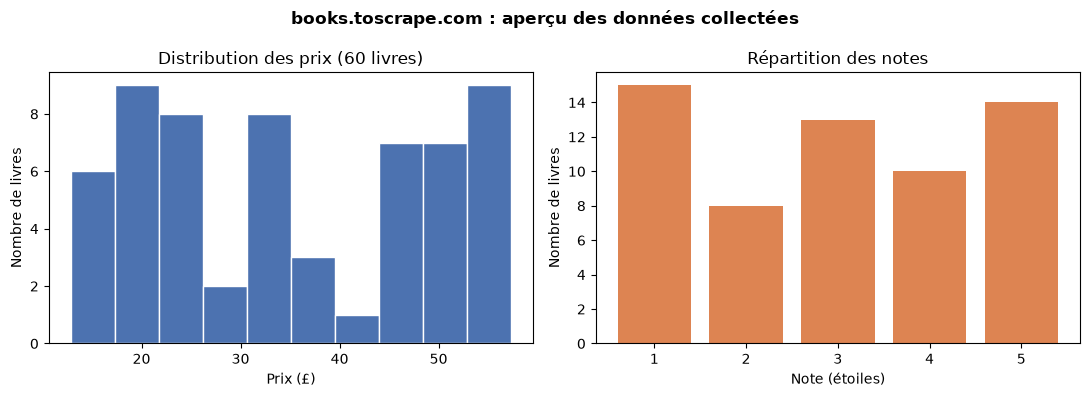

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("data")
df_books = pd.read_csv(DATA_DIR / "books.csv")
ASSETS_DIR = Path("assets")
ASSETS_DIR.mkdir(exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Distribution des prix
axes[0].hist(df_books["price_gbp"], bins=10, color="#4C72B0", edgecolor="white")
axes[0].set_title(f"Distribution des prix ({len(df_books)} livres)")
axes[0].set_xlabel("Prix (£)")
axes[0].set_ylabel("Nombre de livres")

# Répartition des notes (1 à 5 étoiles)
rating_counts = df_books["rating"].value_counts().reindex(range(1, 6), fill_value=0)
axes[1].bar(rating_counts.index, rating_counts.values, color="#DD8452")
axes[1].set_title("Répartition des notes")
axes[1].set_xlabel("Note (étoiles)")
axes[1].set_ylabel("Nombre de livres")
axes[1].set_xticks(range(1, 6))

fig.suptitle("books.toscrape.com : aperçu des données collectées", fontweight="bold")
fig.tight_layout()
fig.savefig(ASSETS_DIR / "books_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## Audit qualité des données collectées

In [11]:
datasets = {"books": df_books, "openlibrary": df_ol, "quotes": df_quotes}

audit = pd.DataFrame({
    name: {
        "lignes": len(df),
        "colonnes": df.shape[1],
        "doublons (lignes)": int(df.duplicated().sum()),
        "valeurs manquantes": int(df.isna().sum().sum()),
    }
    for name, df in datasets.items()
}).T
audit

,lignes,colonnes,doublons (lignes),valeurs manquantes
books,60,5,0,0
openlibrary,50,4,0,0
quotes,20,4,0,0


In [ ]:
# Quelques signaux à surveiller avant le Data Mining
print("Livres Open Library sans auteur      :", df_ol["authors"].isna().sum())
print("Livres Open Library sans année       :", df_ol["first_publish_year"].isna().sum())
print("Titres Open Library en double        :", df_ol["title"].str.lower().duplicated().sum())
print("Disponibilités distinctes (books)    :", df_books["availability"].unique())
print("Nombre de tags distincts (quotes)    :", df_quotes["tags"].str.split("|").explode().nunique())

Livres Open Library sans auteur      : 0
Livres Open Library sans année       : 0
Titres Open Library en double        : 10
Disponibilités distinctes (books)    : <ArrowStringArray>
['In stock']
Length: 1, dtype: str
Nombre de tags distincts (quotes)    : 50


## Question de conclusion

**Les données extraites sont-elles directement exploitables pour le Data Mining ?**

**Pas directement.** L'audit montre des données propres en apparence : 0 valeur manquante et 0 ligne en double dans les trois fichiers (60 livres, 50 résultats Open Library, 20 citations). Elles posent pourtant trois problèmes qui fausseraient une analyse :

- **10 titres en double sur 50** dans Open Library (20 %). Ce sont des œuvres ou éditions différentes portant le même titre, invisibles à un test de doublon ligne par ligne.
- La colonne `availability` vaut **« In stock » pour les 60 livres**. Une variable constante n'apporte aucune information à un modèle.
- **50 tags distincts pour seulement 20 citations**. Ce sont des données multi-valuées et très dispersées.

À cela s'ajoutent des échelles différentes (prix de 12,84 à 57,31 £, notes de 1 à 5) et du texte brut.

**Trois opérations de prétraitement :**

1. **Dédoublonnage sur le contenu.** Normaliser les titres (minuscules, ponctuation, espaces) puis regrouper les doublons Open Library, par exemple en gardant la première édition ou celle qui a le plus de métadonnées. Le code gère déjà les champs manquants (`None`), car l'API peut en renvoyer pour d'autres requêtes.
2. **Sélection et encodage des variables.** Supprimer `availability`, dont la variance est nulle. Encoder les tags en variables binaires (`MultiLabelBinarizer`) en ne gardant que les plus fréquents, pour éviter une matrice trop creuse avec 50 colonnes pour 20 lignes.
3. **Normalisation et nettoyage du texte.** Mettre `price_gbp` et `rating` à la même échelle (min-max ou standardisation) avant tout algorithme basé sur des distances (k-means, k-NN). Pour les citations, retirer les guillemets typographiques `“ ”`, passer en minuscules, enlever les mots vides, puis vectoriser (TF-IDF).